# `seg.evaluate_segmentation` vs `cellpose.metrics`

Astrolabe's `evaluate_segmentation` computes COCO-style instance segmentation metrics (precision/recall/F1/Dice) via IoU-threshold optimal bipartite matching (the Hungarian algorithm). This notebook validates it against `cellpose.metrics.average_precision`, which is built on the same underlying matching algorithm family as `stardist.matching` (the originally planned reference, which cannot install on Python 3.12) and returns raw `tp`/`fp`/`fn` counts per threshold, letting this notebook derive the same precision/recall/F1 astrolabe reports directly.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
from skimage.draw import polygon2mask
import astrolabe as ab
import cellpose.metrics as cpm


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

Synthetic label images, following `tests/test_seg_eval.py`'s own fixture
pattern (deterministic square geometry with controlled overlaps) — this
benchmarks metric-computation correctness on known ground truth, not
biological realism.


In [2]:
def square_mask(shape, top, left, size, label):
    mask = np.zeros(shape, dtype=np.int32)
    poly = np.array(
        [[top, left], [top, left + size], [top + size, left + size], [top + size, left]],
        dtype=np.float64,
    )
    mask[polygon2mask(shape, poly)] = label
    return mask, poly

shape = (120, 120)
# Five ground-truth cells; predictions below are offset by a controlled
# amount per cell so IoU spans a realistic range, not just 0 or 1.
true_specs = [(10, 10, 20), (10, 50, 20), (50, 10, 15), (50, 50, 25), (85, 85, 15)]
offsets = [(0, 0), (2, 1), (4, 4), (1, -2), (8, 8)]  # last one barely overlaps

true_masks = np.zeros(shape, dtype=np.int32)
pred_polys = []
for i, ((top, left, size), (dy, dx)) in enumerate(zip(true_specs, offsets), start=1):
    m, poly = square_mask(shape, top, left, size, label=i)
    true_masks = np.maximum(true_masks, m)
    pred_poly_yx = poly + np.array([dy, dx])
    pred_polys.append(pred_poly_yx[:, [1, 0]])  # [x, y] order for evaluate_segmentation

pred_boundaries = np.array(pred_polys)
pred_boundaries.shape, true_masks.shape


((5, 4, 2), (120, 120))

## Astrolabe: `seg.evaluate_segmentation`, swept over COCO thresholds


In [3]:
thresholds = np.arange(0.5, 1.0, 0.05)
_t0 = time.perf_counter()
astro_rows = [
    {"threshold": t, **ab.seg.evaluate_segmentation(pred_boundaries, true_masks, pixel_size_um=1.0, iou_threshold=t)}
    for t in thresholds
]
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime ({len(thresholds)} thresholds, each its own call): {t_astro_s:.4f}s")
import pandas as pd
astro_df = pd.DataFrame(astro_rows)
astro_df[["threshold", "precision", "recall", "f1", "n_tp"]]


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


...

INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


INFO:astrolabe.seg._eval:evaluate_segmentation: 5 predicted vs 5 ground-truth instances


astrolabe runtime (10 thresholds, each its own call): 0.0166s


,threshold,precision,recall,f1,n_tp
0,0.50,0.6,0.6,0.6,3
1,0.55,0.6,0.6,0.6,3
2,0.60,0.6,0.6,0.6,3
3,0.65,0.6,0.6,0.6,3
4,0.70,0.6,0.6,0.6,3
5,0.75,0.6,0.6,0.6,3
6,0.80,0.2,0.2,0.2,1
7,0.85,0.2,0.2,0.2,1
8,0.90,0.2,0.2,0.2,1
9,0.95,0.2,0.2,0.2,1


## Reference: `cellpose.metrics.average_precision` on the same rasterized masks

Astrolabe's predicted polygons are rasterized the same way
`evaluate_segmentation` itself does internally (`skimage.draw.polygon2mask`)
so both tools match on identical pixel masks, not on two different
rasterizations of the same polygons.


In [4]:
_t0 = time.perf_counter()
pred_masks = np.zeros(shape, dtype=np.int32)
for i, poly_xy in enumerate(pred_polys, start=1):
    poly_yx = poly_xy[:, [1, 0]]
    pred_masks[polygon2mask(shape, poly_yx)] = i

ap, tp, fp, fn = cpm.average_precision(true_masks, pred_masks, threshold=list(thresholds))
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime (rasterization once + all {len(thresholds)} thresholds in one call): {t_ref_s:.4f}s")
tp, fp, fn = tp.ravel(), fp.ravel(), fn.ravel()
with np.errstate(divide="ignore", invalid="ignore"):
    precision_ref = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
    recall_ref = np.where(tp + fn > 0, tp / (tp + fn), 0.0)
    f1_ref = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
ref_df = pd.DataFrame({"threshold": thresholds, "precision_ref": precision_ref, "recall_ref": recall_ref, "f1_ref": f1_ref, "tp_ref": tp})
ref_df


reference runtime (rasterization once + all 10 thresholds in one call): 0.0025s


,threshold,precision_ref,recall_ref,f1_ref,tp_ref
0,0.50,0.6,0.6,0.6,3.0
1,0.55,0.6,0.6,0.6,3.0
2,0.60,0.6,0.6,0.6,3.0
3,0.65,0.6,0.6,0.6,3.0
4,0.70,0.6,0.6,0.6,3.0
5,0.75,0.6,0.6,0.6,3.0
6,0.80,0.2,0.2,0.2,1.0
7,0.85,0.2,0.2,0.2,1.0
8,0.90,0.2,0.2,0.2,1.0
9,0.95,0.2,0.2,0.2,1.0


## Agreement


tp counts match at every threshold: True
Pearson r (F1 across thresholds) = 1.000000, max |diff| = 2.38e-08
Runtime: astrolabe 0.0166s vs cellpose.metrics 0.0025s (6.6x astrolabe slower) -- not apples-to-apples: astrolabe re-rasterizes pred_boundaries and re-matches per threshold call (10 separate calls), while cellpose.metrics rasterizes once and sweeps every threshold internally in a single call.


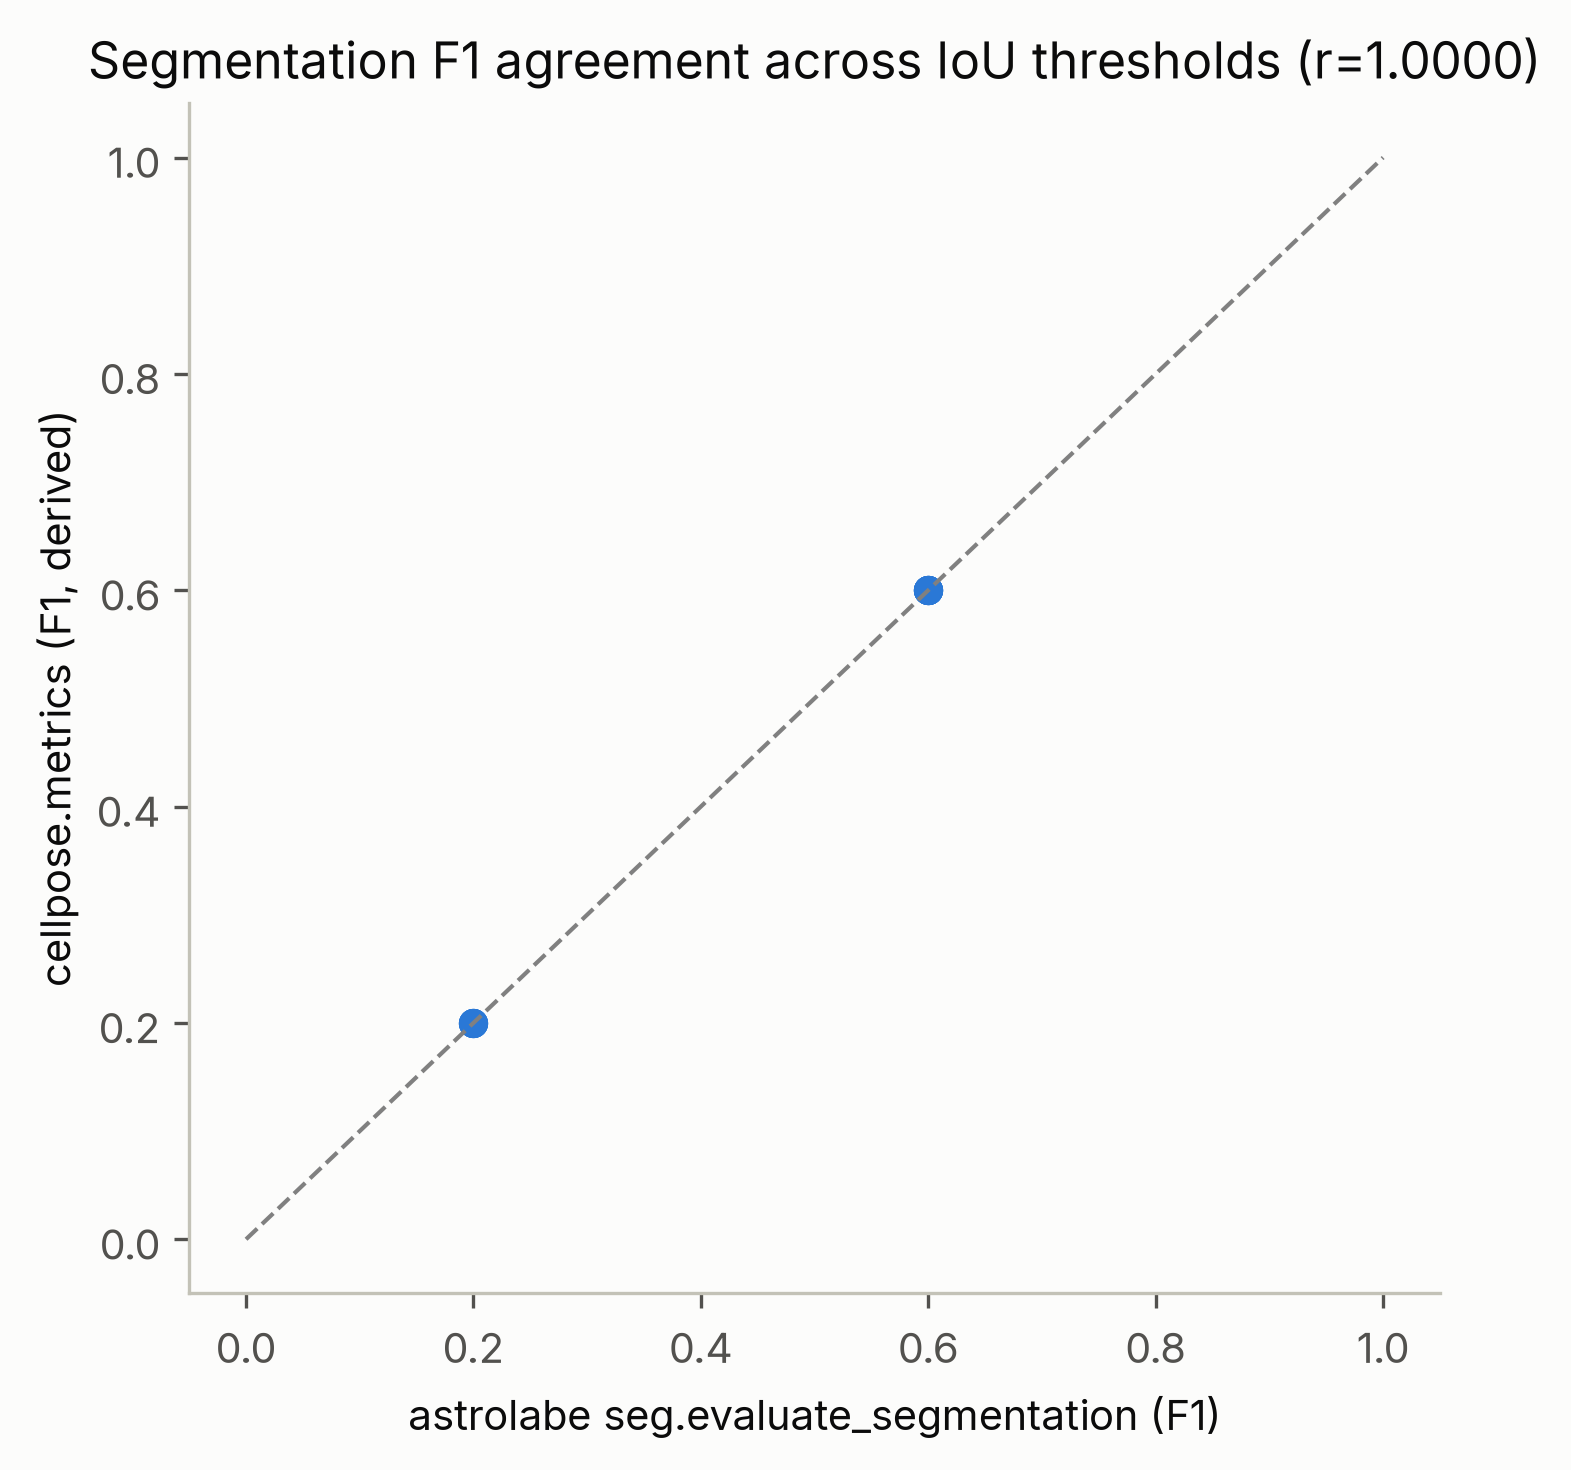

In [5]:
merged = astro_df.merge(ref_df, on="threshold")
r_f1 = np.corrcoef(merged["f1"], merged["f1_ref"])[0, 1]
max_diff_f1 = float((merged["f1"] - merged["f1_ref"]).abs().max())
tp_match = bool((merged["n_tp"].to_numpy() == merged["tp_ref"].to_numpy()).all())
print(f"tp counts match at every threshold: {tp_match}")
print(f"Pearson r (F1 across thresholds) = {r_f1:.6f}, max |diff| = {max_diff_f1:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs cellpose.metrics {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"not apples-to-apples: astrolabe re-rasterizes pred_boundaries and re-matches per "
      f"threshold call ({len(thresholds)} separate calls), while cellpose.metrics rasterizes once "
      f"and sweeps every threshold internally in a single call.")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
ax.scatter(merged["f1"], merged["f1_ref"])
ax.set_xlabel("astrolabe seg.evaluate_segmentation (F1)")
ax.set_ylabel("cellpose.metrics (F1, derived)")
ax.set_title(f"Segmentation F1 agreement across IoU thresholds (r={r_f1:.4f})")
fig.tight_layout()
plt.show()


## Interpretation

Both implementations use IoU-threshold optimal bipartite matching (the
Hungarian algorithm) on identical rasterized masks, so an exact match on
`tp` at every threshold — and near-exact agreement on the derived
precision/recall/F1 — is the expected result, validating that astrolabe's
matching logic is a faithful COCO-style implementation, not merely
correlated with one.
